# M03-L05 — Imagens como Matriz de Números: Canais, Escala de Cinza e Threshold

**Antes de começar:**
1. Clique em **Arquivo → Salvar uma cópia no Drive** para ter sua própria versão editável.
2. Execute as células **em ordem**, de cima para baixo. Pular células pode gerar erros.
3. Sempre que aparecer `# --- Atividade: seu código aqui ---`, complete o exercício antes de seguir.


## Retomando a M03-L04

Na lição anterior, você treinou classificadores clássicos no dataset Iris e avaliou os resultados com matriz de confusão, `classification_report` e `random_state`. Hoje vamos trabalhar com as **fotografias reais** das três espécies de Iris (`setosa`, `versicolor`, `virginica`) e ver como uma imagem também é dado numérico.

## Atividade 1 — Baixando e carregando as fotos das flores

A célula abaixo é só "encanamento": ela baixa os três arquivos de imagem e salva no ambiente do Colab. Usamos `urllib.request` (biblioteca padrão do Python) em vez de `!wget`, porque `!wget` não funciona se você (ou um colega) rodar este notebook fora do Colab, por exemplo no Windows.

In [1]:
import urllib.request

imagens = {
    "iris_setosa.jpg": "https://upload.wikimedia.org/wikipedia/commons/5/56/Kosaciec_szczecinkowaty_Iris_setosa.jpg",
    "iris_versicolor.jpg": "https://upload.wikimedia.org/wikipedia/commons/4/41/Iris_versicolor_3.jpg",
    "iris_virginica.jpg": "https://upload.wikimedia.org/wikipedia/commons/9/9f/Iris_virginica.jpg",
}

for nome_arquivo, url in imagens.items():
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as response:
        with open(nome_arquivo, "wb") as f:
            f.write(response.read())

print("Imagens baixadas:", list(imagens.keys()))


Imagens baixadas: ['iris_setosa.jpg', 'iris_versicolor.jpg', 'iris_virginica.jpg']


Agora vamos carregar as três imagens com `plt.imread` e conferir o `.shape` de cada uma.

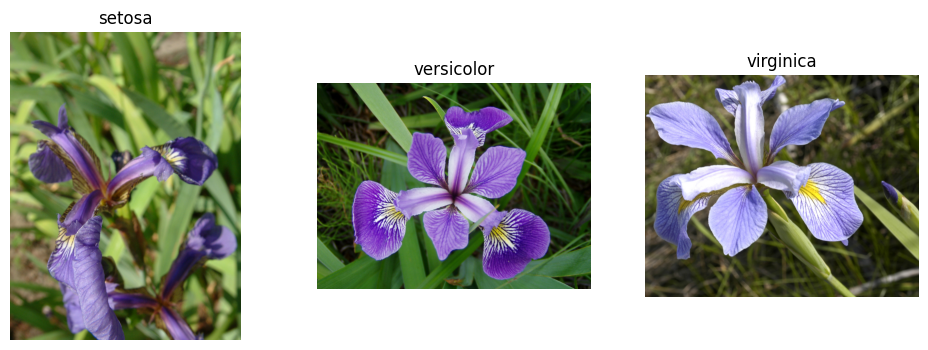

setosa: (1280, 960, 3)
versicolor: (1488, 1984, 3)
virginica: (1950, 2395, 3)


In [2]:
import matplotlib.pyplot as plt

img_setosa = plt.imread("iris_setosa.jpg")
img_versicolor = plt.imread("iris_versicolor.jpg")
img_virginica = plt.imread("iris_virginica.jpg")

fig, eixos = plt.subplots(1, 3, figsize=(12, 4))
eixos[0].imshow(img_setosa)
eixos[0].set_title("setosa")
eixos[1].imshow(img_versicolor)
eixos[1].set_title("versicolor")
eixos[2].imshow(img_virginica)
eixos[2].set_title("virginica")
for eixo in eixos:
    eixo.axis("off")
plt.show()

print("setosa:", img_setosa.shape)
print("versicolor:", img_versicolor.shape)
print("virginica:", img_virginica.shape)


**Pergunta rápida:** qual desses três números do `.shape` é a altura, qual é a largura, e qual é o número de canais? Escreva sua resposta em uma frase curta na célula abaixo (célula de texto, não precisa rodar código).

_Sua resposta:_

## Exemplo guiado 1 — Reduzindo a resolução por fatiamento

As fotos vieram em alta resolução. Vamos reduzir usando fatiamento com passo — a mesma ferramenta que você já usa para pegar elementos de uma lista pulando posições, agora aplicada às duas primeiras dimensões da imagem.

Antes: (1280, 960, 3)
Depois: (160, 120, 3)


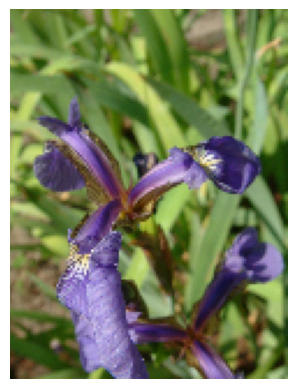

In [3]:
n = 8
img_setosa_reduzida = img_setosa[::n, ::n]

print("Antes:", img_setosa.shape)
print("Depois:", img_setosa_reduzida.shape)

plt.imshow(img_setosa_reduzida)
plt.axis("off")
plt.show()


## Atividade 2 — Reduza as fotos restantes

Reduza a resolução de `img_versicolor` e `img_virginica`, escolhendo um valor de `n` razoável para cada uma. Você pode usar o mesmo `n` da foto de `setosa` ou ajustar, justificando sua escolha com base no `.shape` original de cada foto.

In [4]:
# --- Atividade: seu código aqui ---
n_versicolor = None  # escolha um valor de n
img_versicolor_reduzida = None  # aplique o fatiamento

n_virginica = None  # escolha um valor de n
img_virginica_reduzida = None  # aplique o fatiamento

# Dica: siga o padrão do exemplo guiado 1 acima.


**Justifique em texto:** por que você escolheu esses valores de `n`? O que aconteceu com o `.shape` de cada imagem depois da redução?

_Sua justificativa:_

## Exemplo guiado 2 — Separando os canais R, G, B

Cada pixel colorido é composto por três valores: vermelho, verde e azul. Vamos separar esses três canais da foto de `setosa` já reduzida.

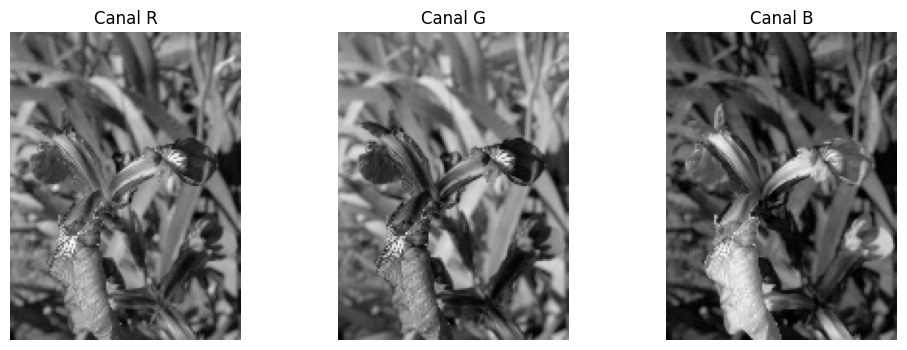

In [5]:
canal_r = img_setosa_reduzida[:, :, 0]
canal_g = img_setosa_reduzida[:, :, 1]
canal_b = img_setosa_reduzida[:, :, 2]

fig, eixos = plt.subplots(1, 3, figsize=(12, 4))
eixos[0].imshow(canal_r, cmap="gray")
eixos[0].set_title("Canal R")
eixos[1].imshow(canal_g, cmap="gray")
eixos[1].set_title("Canal G")
eixos[2].imshow(canal_b, cmap="gray")
eixos[2].set_title("Canal B")
for eixo in eixos:
    eixo.axis("off")
plt.show()


## Atividade 3 — Canais e escala de cinza para as demais fotos

1. Separe os canais R, G, B de `img_versicolor_reduzida` e `img_virginica_reduzida` (siga o padrão do exemplo guiado 2).
2. Converta **as três fotos reduzidas** (`setosa`, `versicolor`, `virginica`) para escala de cinza, calculando a média dos três canais (`.mean(axis=2)`).

In [6]:
# --- Atividade: seus canais aqui ---
# Canais de versicolor
# Canais de virginica


# --- Atividade: escala de cinza das três fotos ---
img_setosa_cinza = None
img_versicolor_cinza = None
img_virginica_cinza = None

# Dica: img_xxx_cinza = img_xxx_reduzida.mean(axis=2)


TypeError: Image data of dtype object cannot be converted to float

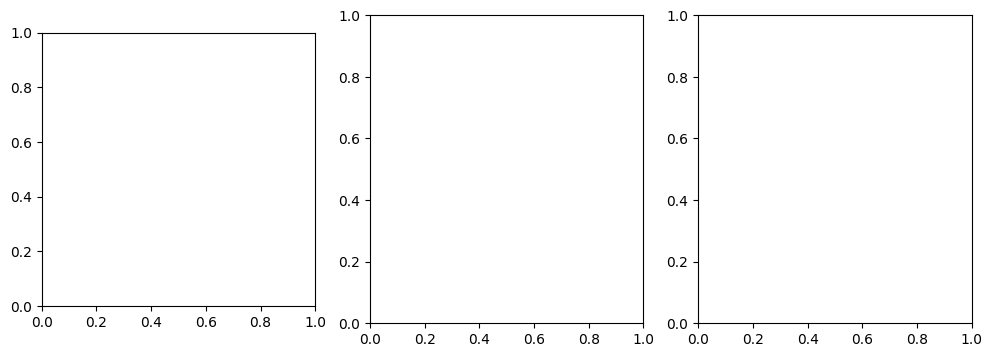

In [7]:
# Visualize as três versões em escala de cinza para conferir seu resultado
fig, eixos = plt.subplots(1, 3, figsize=(12, 4))
eixos[0].imshow(img_setosa_cinza, cmap="gray")
eixos[0].set_title("setosa (cinza)")
eixos[1].imshow(img_versicolor_cinza, cmap="gray")
eixos[1].set_title("versicolor (cinza)")
eixos[2].imshow(img_virginica_cinza, cmap="gray")
eixos[2].set_title("virginica (cinza)")
for eixo in eixos:
    eixo.axis("off")
plt.show()


## Exemplo guiado 3 — Ruído visual simples (com seed fixa)

Assim como na M03-L04 você comprovou que resultados mudam sem `random_state` fixo, aqui usamos `np.random.seed` para garantir que o ruído gerado seja sempre o mesmo.

In [ ]:
import numpy as np

np.random.seed(42)
ruido = np.random.normal(loc=0, scale=15, size=img_setosa_cinza.shape)
img_setosa_com_ruido = img_setosa_cinza + ruido

fig, eixos = plt.subplots(1, 2, figsize=(8, 4))
eixos[0].imshow(img_setosa_cinza, cmap="gray")
eixos[0].set_title("Sem ruído")
eixos[1].imshow(img_setosa_com_ruido, cmap="gray")
eixos[1].set_title("Com ruído (seed=42)")
for eixo in eixos:
    eixo.axis("off")
plt.show()


## Exemplo guiado 4 — Threshold e máscara binária

Antes de escolher um valor de corte, é sempre bom conferir o intervalo real de valores da imagem em escala de cinza.

In [ ]:
print("Mínimo (setosa cinza):", img_setosa_cinza.min())
print("Máximo (setosa cinza):", img_setosa_cinza.max())

limiar = 140
mascara_setosa = img_setosa_cinza > limiar

plt.imshow(mascara_setosa, cmap="gray")
plt.axis("off")
plt.title(f"Máscara binária (limiar = {limiar})")
plt.show()


**Atenção:** essa é uma foto real, com fundo irregular (folhas, sombra). O threshold escolhido acima pode não separar a flor do fundo perfeitamente — isso é esperado, não é um erro seu. Experimente mudar o valor de `limiar` na célula acima e observe como a máscara muda.

## Atividade 4 — Threshold, máscara e proporção segmentada para as três fotos

1. Aplique threshold e gere a máscara binária para `versicolor` e `virginica` (a de `setosa` já foi feita acima).
2. Calcule a proporção de pixels segmentados (`.mean()` da máscara booleana) das **três** fotos.
3. Organize os três resultados em uma tabela simples (pode ser um dicionário Python ou um `DataFrame`).

In [ ]:
# --- Atividade: seu código aqui ---
# 1) Threshold e máscara para versicolor e virginica
limiar_versicolor = None
mascara_versicolor = None

limiar_virginica = None
mascara_virginica = None

# 2) Proporção de pixels segmentados das três fotos
proporcao_setosa = mascara_setosa.mean()
proporcao_versicolor = None
proporcao_virginica = None

# 3) Tabela simples com os três resultados
resultados = {
    "setosa": proporcao_setosa,
    "versicolor": proporcao_versicolor,
    "virginica": proporcao_virginica,
}
print(resultados)


## Exemplo de erro comum

A célula abaixo tem **dois erros propositais**. Rode e observe o que acontece (ou o que fica visualmente estranho) antes de corrigir.

In [ ]:
# Erro 1: esqueceu cmap="gray"
plt.imshow(img_setosa_cinza)
plt.axis("off")
plt.show()

# Erro 2: threshold fora do intervalo real de valores da imagem
limiar_errado = 300
mascara_errada = img_setosa_cinza > limiar_errado
plt.imshow(mascara_errada, cmap="gray")
plt.axis("off")
plt.show()


## Exercício de correção de erro

Corrija os dois problemas da célula acima:
1. Adicione `cmap="gray"` na primeira exibição.
2. Escolha um valor de threshold dentro do intervalo real de `img_setosa_cinza` (confira `.min()` e `.max()`) e observe como a máscara muda em relação à do erro.

In [ ]:
# --- Correção: seu código aqui ---


## Desafio extra (opcional)

Compare pelo menos 2 valores diferentes de threshold na mesma foto: calcule a proporção segmentada para cada valor e escreva, em texto, qual valor você acha que separa melhor a flor do fundo e por quê.

Opcionalmente, tente aplicar o threshold direto sobre um único canal de cor (por exemplo, `canal_r`) em vez da escala de cinza, e compare o resultado com a máscara obtida a partir da escala de cinza.

Não use métodos automáticos de threshold (como Otsu) nem bibliotecas de visão computacional — apenas NumPy e matplotlib.

In [ ]:
# --- Desafio extra: seu código aqui (opcional) ---


## Reflexão final

Responda em poucas frases:

1. O que mudou, na prática, entre escolher um threshold para uma imagem sintética (controlada) e para uma foto real como as de hoje?
2. Lembra do cenário de custo de falso positivo em `virginica`, discutido na M03-L04? Se uma máscara de segmentação classificar erroneamente pixels de fundo como "flor" (ou vice-versa), que tipo de problema isso poderia causar em uma aplicação real que dependesse dessa segmentação?

_Sua reflexão:_

## Checklist de conclusão

- [ ] Baixei e carreguei as três fotografias reais fornecidas.
- [ ] Reduzi a resolução das três fotos por fatiamento com passo.
- [ ] Separei os canais de cor de ao menos uma foto.
- [ ] Converti as três fotos para escala de cinza.
- [ ] Apliquei threshold e gerei máscara binária para as três fotos.
- [ ] Calculei a proporção de pixels segmentados das três fotos.
- [ ] Corrigi o erro simples proposto.
- [ ] Preenchi a reflexão final.
- [ ] Finalizei o laboratório da lição.

## Orientação de entrega

Entregue este notebook executado (todas as células rodadas, na ordem, sem erros) com:
* as três fotos carregadas e reduzidas;
* canais separados de ao menos uma foto;
* as três fotos em escala de cinza;
* máscara binária e proporção de pixels segmentados das três fotos;
* o erro proposto corrigido;
* a reflexão final preenchida.

Guarde bem este notebook: as três imagens processadas hoje (`setosa`, `versicolor`, `virginica`) serão reaproveitadas na próxima lição, M03-L06, para extrair features e treinar classificadores sobre imagens.